# TP 4 - Reconnaissance d'espèces de fleurs par classification bayésienne


M1 CSAA

Novembre 2021

L'objectif est de réaliser un classifieur bayésien permettant de classer des images de trois espèces de fleurs.


Télécharger tout d'abord les images de fleurs :

In [ ]:
!wget -q https://www.irit.fr/~Thomas.Pellegrini/ens/M1CSAA/Fleurs.zip
!unzip -q Fleurs.zip
!rm Fleurs.zip

Importer les modules nécessaires :

In [2]:
import matplotlib.image as img
import numpy as np

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
from matplotlib.colors import ListedColormap

import seaborn as sns

from math import pi as PI

from sklearn.naive_bayes import GaussianNB
from sklearn import metrics


La cellule suivante affiche des images de pensées, d'oeillets et de chrysanthèmes. Vous constatez que ces images n'ont pas toutes la même taille.

In [8]:
types_fleur = ["ch", "oe", "pe"]

def lire_image(chemin_fichier):
    return np.array(255*img.imread(chemin_fichier), dtype=int)


def affichage_images(type_fleur='ch', n_fleurs=10):
    """Affichage d'images de fleurs

    Arguments:
        type_fleur='ch', 'oe', 'pe'
        n_fleurs: nombre de fleurs à afficher dans la figure
    """

    for i in range(n_fleurs):
        path = "./Fleurs/"
        name = type_fleur + str(i + 1) + ".png"
        print(name)
        image = lire_image(name)
        plt.figure(1)
        plt.subplot(3, 4, i + 1)
        plt.imshow(image)

    plt.show()

affichage_images(type_fleur='ch', n_fleurs=10)

ch.png


FileNotFoundError: [Errno 2] No such file or directory: 'ch.png'

## Prétraitement : calcul de la couleur moyenne d'une image

Dans un premier temps, vous allez classer les images selon la couleur moyenne de chaque espèce de fleurs. En chaque pixel de chaque image, les trois niveaux de couleur $(R,V,B) \in [0,255]^3$ sont d'abord transformés en ***niveaux de couleur normalisés*** $(r,v,b)$, qui sont définis de la manière suivante :

\begin{equation*}
	(r,v,b) = \frac{1}{\max\{1,R+V+B\}}\,(R,V,B)
\end{equation*}

Le principal intérêt des niveaux de couleur normalisés est que deux valeurs parmi $(r,v,b)$ permettent de déduire la troisième, puisque $r+v+b=1$, sauf dans le cas exceptionnel où $(r,v,b)=(0,0,0)$. Une image est donc caractérisée par les moyennes $(\bar{r},\bar{v},\bar{b})$, ou plus simplement par $(\bar{r},\bar{v})$, puisque $\bar{r}+\bar{v}+\bar{b}=1$, c'est-à-dire par un vecteur $\textbf{x}=[\bar{r},\bar{v}]\in\mathbb{R}^2$ qu'on appelle sa ***couleur moyenne***. Compte tenu des différences de couleurs moyennes entre les trois espèces de fleurs, on postule que ce vecteur suffira à les distinguer.

Écrire dans la cellule suivante la fonction `Pretraitement`, qui calcule la couleur moyenne d'une image.

La fonction `Pretraitement` est censée normaliser les couleurs d'une image et calculer les couleurs moyennes $[\bar{r},\bar{v}]$ dans $\mathbb{R}^2$ de l'image.

In [4]:
def Pretraitement(image):
    image = image.astype(float)
    print(image)
    sum_rgb = np.sum(image, axis=2)
    # si on veut garder les 3 dims: sum_rgb = np.sum(image, axis=2, keepdims= True)

    sum_rgb[sum_rgb == 0] = 1

    r = image[:, :, 0] / sum_rgb
    v = image[:, :, 1] / sum_rgb

    mean_r = np.mean(r)
    mean_v = np.mean(v)

    return np.array([mean_r, mean_v])

Compléter la fonction `calcule_moy_toutes_images` qui retourne un dictionnaire dont les clés sont les trois espèces de fleurs et les valeurs associées une matrice numpy contenant les couleurs moyennes $[\bar{r},\bar{v}]$ des `n_fleurs` de l'espèce clé.  


In [9]:
def calcule_moy_toutes_images(n_fleurs=10):

    types_fleur = ["ch", "oe", "pe"]
    feat_dic = {"ch":[], "oe": [], "pe": []}

    for t in types_fleur:
        for i in range(n_fleurs):
            path = "./Fleurs/"
            name = path + t + str(i + 1) + ".png"
            image = lire_image(name)
            mean_color = Pretraitement(image)
            feat_dic[t].append(mean_color)

    for t in types_fleur:
        feat_dic[t] = np.array(feat_dic[t])

    return feat_dic


Affichez les couleurs moyennes de l'ensemble des images de fleurs sous la forme de trois nuages de points de $\mathbb{R}^2$.



In [10]:
    feat_dic = calcule_moy_toutes_images()
    print(feat_dic)
    plt.figure()
    plt.plot(feat_dic["ch"][:, 0], feat_dic["ch"][:, 1], "xr", label='ch')
    plt.plot(feat_dic["oe"][:, 0], feat_dic["oe"][:, 1], "ob", label='oe')
    plt.plot(feat_dic["pe"][:, 0], feat_dic["pe"][:, 1], "+g", label='pe')
    plt.legend()
    plt.show()


FileNotFoundError: [Errno 2] No such file or directory: './Fleurs/ch1.png'


La couleur moyenne vous semble-t-elle une caractéristique suffisamment discriminante de ces trois espèces de fleurs ?

R: Pour les fleurs du type ch oui mais pour les oe et pe non

# Classification avec GaussianNB de sklearn : le classifieur bayésien naïf gaussien

In [ ]:
def split_data(feat_dic):

    nb_train_fleur = 6
    nb_test_fleur = 10 - nb_train_fleur
    types_fleur = ["ch", "oe", "pe"]
    x_train, y_train, x_test, y_test = [], [], [], []
    for t in types_fleur:
        x_train.extend(feat_dic[t][0:nb_train_fleur])
        y_train.extend([types_fleur.index(t)]*nb_train_fleur)
        x_test.extend(feat_dic[t][nb_train_fleur:])
        y_test.extend([types_fleur.index(t)]*nb_test_fleur)
    return np.asarray(x_train), np.asarray(y_train), np.asarray(x_test), np.asarray(y_test)

In [ ]:
x_train, y_train, x_test, y_test = split_data(feat_dic)

In [ ]:
x_train.shape, y_train, x_test.shape, y_test

((18, 2),
 array([0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2]),
 (12, 2),
 array([0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 2, 2]))

Instancier un classifieur GaussianNB et l'entraîner sur le sous-ensemble de train. Calculer sa précision sur les sous-ensembles de train et de test.

In [ ]:
classifieur = GaussianNB()

classifieur.fit(x_train, y_train)

accuracy_train = classifieur.score(x_train, y_train)
print(f"Accuracy on training set: {accuracy_train:.2f}")

accuracy_test = classifieur.score(x_test, y_test)
print(f"Accuracy on test set: {accuracy_test:.2f}")

Accuracy on training set: 0.89
Accuracy on test set: 0.75


Cette cellule affiche la matrice de confusion sur le sous-ensemble de test.

In [ ]:
# disp = metrics.plot_confusion_matrix(clf, x_test, y_test,
#                                  display_labels=["ch", "oe", "pe"],
#                                  cmap=plt.cm.Blues,
#                                  normalize=None)
# disp.ax_.set_title('Matrice de Confusion GaussianNB');

# Ne marche pas car ne reconnait pas la fonction splot_confusion_matrix

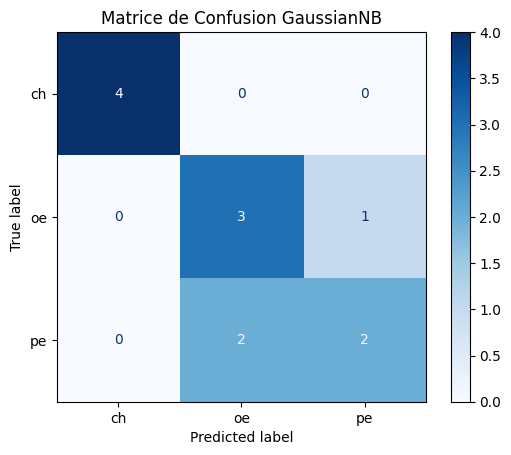

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay.from_estimator(classifieur, x_test, y_test,
                                 display_labels=["ch", "oe", "pe"],
                                 cmap=plt.cm.Blues,
                                 normalize=None)
disp.ax_.set_title('Matrice de Confusion GaussianNB');

Commenter cette matrice de confusion.

R: Comme on a vu lors de l'affichage des nuages de points les points de la classe "ch" sont bien classés tandis que dans les autres classes "oe" et "pe" il y a des prédictions ratées

À l'aide de la méthode `predict`, déterminer la prédiction que fait le classifieur pour le dernier exemple de x_test.

In [ ]:
prediction_dernier_ex = classifieur.predict(x_test[-1].reshape(1, -1))
print(f"Prediction for the last example in x_test: {prediction_dernier_ex}")

Prediction for the last example in x_test: [1]


À l'aide de la méthode `predict_proba`, calculer les probabilités des trois classes pour le dernier exemple de x_test.

In [ ]:
proba_dernier_ex = classifieur.predict_proba(x_test[-1].reshape(1, -1))
print(f"Probabilities for the last example in x_test: {proba_dernier_ex}")

Probabilities for the last example in x_test: [[1.64489809e-44 7.40270502e-01 2.59729498e-01]]


Cette cellule trace les régions de décision du classifieur.

(0.27084850583486825, 0.39084850583486835)

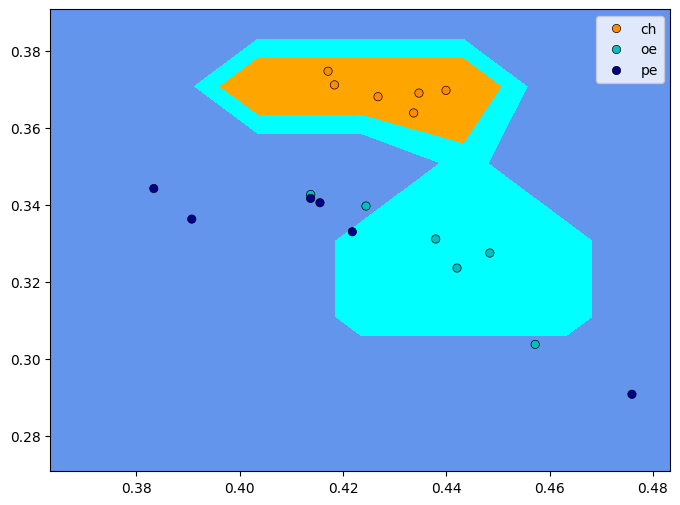

In [ ]:
# Plot the decision boundary. For that, we will assign a color to each
# point in the mesh [x_min, x_max]x[y_min, y_max]

h = 0.02  # step size in the mesh
x_min, x_max = x_train[:, 0].min() - 0.02, x_train[:, 0].max() + 0.02
y_min, y_max = x_train[:, 1].min() - 0.02, x_train[:, 1].max() + 0.02
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = classifieur.predict(np.c_[xx.ravel(), yy.ravel()])

# Put the result into a color plot
Z = Z.reshape(xx.shape)
plt.figure(figsize=(8, 6))
cmap_light = ListedColormap(["orange", "cyan", "cornflowerblue"])
cmap_bold = ["darkorange", "c", "darkblue"]

plt.contourf(xx, yy, Z, cmap=cmap_light)

target_names = [types_fleur[y_train[i]] for i in range(y_train.shape[0]) ]
sns.scatterplot(
    x=x_train[:, 0],
    y=x_train[:, 1],
    hue=target_names,
    palette=cmap_bold,
    alpha=1.0,
    edgecolor="black",
)

plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())


Enfin, il est possible de récupérer les moyennes et les variances des gaussiennes du classifieur pour chacune des trois classes :

In [ ]:
print("Moyennes des Gaussiennes : \n", classifieur.theta_)
print("Variances des Gaussiennes : \n", classifieur.var_)

Moyennes des Gaussiennes : 
 [[0.42842749 0.36948377]
 [0.43730412 0.32810697]
 [0.41685432 0.33114589]]
Variances des Gaussiennes : 
 [[7.19750358e-05 1.06409568e-05]
 [2.10376216e-04 1.61625487e-04]
 [8.88098308e-04 3.38142579e-04]]


On voit que pour chaque classe, il y a deux variances associées aux deux attributs $\bar{r},\bar{v}$. Si nous utilisions une classifieur Gaussien sans faire l'hypothèse "naïve", nous aurions une matrice $2 \times 2$ pour caractériser la variance.

Comme vu en cours, le classifieur naïf fait l'hypothèse qu'il n'y a pas d'interaction entre les attributs. Les attributs sont supposés indépendants entre eux.

## Votre classifieur Gaussien

Dans cette partie du TP, vous allez implémenter votre propre classifieur gaussien, sans faire l'hypothèse naïve.

Les trois nuages de points précédents vont donc être modélisés par des lois normales bidimensionnelles. Il est rappelé que la densité de probabilité d'une loi normale s'écrit, en dimension $d$ :

\begin{equation}
	p(\textbf{x})=\cfrac{1}{(2\pi)^{d/2}\,(\det\Sigma)^{1/2}} \,\exp\left\{-\cfrac{1}{2}\,(\textbf{x}-\mu)\Sigma^{-1}(\textbf{x}-\mu)^\top\right\}
\end{equation}

où :

- $\mu$ désigne l'espérance (la moyenne) des vecteurs $\textbf{x}\in\mathbb{R}^d$ : $\mu = E[\textbf{x}]= \int\textbf{x}\,p(\textbf{x})\,d \textbf{x}$.

- $\Sigma$ désigne la matrice de variance/covariance : $\Sigma = E[(\textbf{x}-\mu)^T(\textbf{x}-\mu)]$.

Dans le cadre bayésien, la vraisemblance de la classe $\omega_i$, qui est caractérisée par la moyenne $\mu_i$ et la matrice de variance/covariance $\Sigma_i$, peut être modélisée par une loi normale analogue à \eqref{eq:loi_normale} :

\begin{equation*}
	p(\textbf{x}|\omega_i) = \frac{1}{(2\pi)^{d/2}\,(\det\Sigma_i)^{1/2}} \,\exp\left\{-\frac{1}{2}\,(\textbf{x}-\mu_i){\Sigma_i}^{-1} (\textbf{x}-\mu_i)^\top\right\} \, \text{, } \quad i\in[1,3]
\end{equation*}

Il faut donc estimer les paramètres $\mu_i$ et $\Sigma_i$ des trois classes correspondant aux trois espèces de fleurs.


Compléter la méthode `fit()` de l'objet `GaussianBayes` :


In [ ]:
class GaussianBayes(object):
    """ Classification bayesienne Gaussienne
    """
    def __init__(self, priors:np.ndarray=None, nb_train_examples=6) -> None:
        self.priors = priors    # a priori probabilities of classes
                                # (n_classes,)

        self.mu = None          #  mean of each feature per class
                                # (n_classes, n_features)
        self.sigma = None       # covariance of each feature per class
                                # (n_classes, n_features, n_features)

        self.nb_train_examples = nb_train_examples


    def fit(self, X:np.ndarray, y:np.ndarray, ) -> None:
        """Learning : estime self.mu et self.sigma

        X : shape (n_data, n_features)
        y : shape (n_data)
        """
        n_classes = len(np.unique(y))
        n_features = X.shape[1]

        self.mu = np.zeros((n_classes, n_features))
        self.sigma = np.zeros((n_classes, n_features, n_features))

        for i in range(n_classes):
            X_class = X[y == i]
            self.mu[i] = np.mean(X_class, axis=0)
            # Calculate covariance matrix, ensuring it's at least 2x2
            if X_class.shape[0] > 1:
                self.sigma[i] = np.cov(X_class.T)
            else:
                # Handle case with only one sample in class (covariance is zero)
                self.sigma[i] = np.zeros((n_features, n_features))


    def predict(self, X:np.ndarray) -> np.ndarray:
        """retourne un vecteur de prédictions sur X contenant les indices des classes prédites

        X shape = [n_samples, n_features]
        maximum log-likelihood or maximum a posteriori
        """
        n_samples = X.shape[0]
        n_classes = self.mu.shape[0]
        log_probabilities = np.zeros((n_samples, n_classes))

        for i in range(n_classes):
            mu = self.mu[i]
            sigma = self.sigma[i]
            # Handle singular covariance matrix by adding a small value to the diagonal
            sigma = sigma + np.eye(sigma.shape[0]) * 1e-6
            det_sigma = np.linalg.det(sigma)
            inv_sigma = np.linalg.inv(sigma)

            for j in range(n_samples):
                x = X[j]
                diff = (x - mu).reshape(-1, 1)
                # Calculate the log likelihood using the formula for multivariate Gaussian distribution
                log_likelihood = -0.5 * (diff.T @ inv_sigma @ diff) - 0.5 * np.log(det_sigma) - (X.shape[1]/2.0)*np.log(2*PI)

                # Add log prior if priors are available
                if self.priors is not None:
                    log_probabilities[j, i] = log_likelihood + np.log(self.priors[i])
                else:
                    log_probabilities[j, i] = log_likelihood


        # Predict the class with the maximum log probability
        predictions = np.argmax(log_probabilities, axis=1)

        return predictions

Instancier le classifieur et l'entraîner sur le sous-ensemble `x_train`:

In [ ]:
classifieur_GB = GaussianBayes()
classifieur_GB.fit(x_train, y_train)

Compléter maintenant la méthode `predict` en n'utilisant pas, dans un premier temps les probabilités a priori.


C'est-à-dire que votre classifieur fait des prédictions selon la règle du maximum de vraisemblance :

consiste à affecter à $\textbf{x}$ la classe $\omega_i$ qui maximise la vraisemblance $p(\textbf{x}|\omega_i)$.


Faire des prédictions sur le sous-ensemble de train et calculer la précision obtenue

In [ ]:
pred = classifieur_GB.predict(x_train)

precision = np.mean(pred == y_train)

print("précision train = %.2f%%"%(precision*100))

#pred

précision train = 83.33%


/tmp/ipython-input-3399679299.py:67: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  log_probabilities[j, i] = log_likelihood


Même question sur le sous-ensemble de test :

In [ ]:
pred = classifieur_GB.predict(x_test)

precision = np.mean(pred == y_test)

print("précision test = %.2f%%"%(precision*100))

#pred

précision test = 66.67%


/tmp/ipython-input-3399679299.py:67: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  log_probabilities[j, i] = log_likelihood


Ce classifieur est-il meilleur ou moins bon que le classifieur naïf ? À votre avis pourquoi ?

Rajoutons maintenant la possibilité d'utiliser les probabilités a priori des classes. Pour cela, modifier la méthode predict.

Pour rappel du cours, la règle de Bayes donne l'expression suivante de la ***probabilité a posteriori*** $p(\omega_i|\textbf{x})$, c'est-à-dire de la probabilité pour que la classe $\omega_i$ contienne $\textbf{x}$ :

\begin{equation}
	p(\omega_i|\textbf{x}) = \frac{p(\textbf{x}|\omega_i)\,p(\omega_i)}{p(\textbf{x})}
\end{equation}

Il semble naturel d'affecter à $\textbf{x}$ la classe $\omega_i$ qui maximise $p(\omega_i|\textbf{x})$. Une telle classification est dite par ***maximum a posteriori*** (MAP).

Sachant que le dénominateur $p(\textbf{x})$ est indépendant de $\omega_i$, il n'est pas nécessaire de le connaître pour trouver le maximum des $p(\omega_i|\textbf{x})$. En revanche, il est nécessaire de connaître la ***probabilité a priori*** $p(\omega_i)$ de chaque classe $\omega_i$, faute de quoi on fait généralement l'hypothèse que les classes sont équiprobables (l'estimateur par maximum a posteriori revient alors à un estimateur par maximum de vraisemblance).


En jouant sur les probabilités a priori des trois classes, vous essaierez de maximiser le pourcentage d'images correctement classées

## Amélioration du classifieur

Même en jouant sur les probabilités a priori, le classifieur obtenu reste décevant. Or, l'observation attentive des images de pensées et d'oeillets, dont les couleurs moyennes sont similaires, montre que ces deux espèces de fleurs ne sont pas structurées de la même façon : les pensées sont plus sombres au centre, c'est-à-dire au niveau du pistil. Cela suggère de ne pas seulement calculer la couleur moyenne des images, mais de scinder chaque image en deux parties complémentaires : le centre $C$ (notion à préciser) et le pourtour $P$ (complémentaire de $C$).

Écrire une nouvelle classe `GaussianBayesBetter` reprenant le principe du classifieur MAP précédent, mais utilisant trois caractéristiques pour décrire une image, à savoir le couple de valeurs $(\bar{r},\bar{v})$ calculées sur le pourtour $P$ et la valeur $\bar{r}$ calculée sur le centre $C$.

In [ ]:
# pour discrimner les 2 derniers types de fleurs
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report

# ===========================================================
#  Classe demandée : GaussianBayesBetter
# ===========================================================

class GaussianBayesBetter:
    """
    Classifieur bayésien MAP amélioré :
    Utilise 3 caractéristiques extraites d'une image :
        - r̄_P : moyenne rouge du pourtour
        - v̄_P : moyenne verte du pourtour
        - r̄_C : moyenne rouge du centre

    Le classifieur applique un modèle Gaussien naïf.
    """

    def __init__(self):
        self.classes = None
        self.means = {}
        self.vars = {}
        self.priors = {}

    # -----------------------------------------------------------
    # Extraction centre / pourtour
    # -----------------------------------------------------------
    def extract_features(self, img):
        """
        img : tableau numpy (H, W, 3)
        Retourne le vecteur (r̄_P, v̄_P, r̄_C)

        Centre C = carré central [H/4 : 3H/4] x [W/4 : 3W/4]
        Pourtour P = reste de l’image
        """
        H, W, _ = img.shape

        h1 = H // 4
        h2 = 3 * H // 4
        w1 = W // 4
        w2 = 3 * W // 4

        centre = img[h1:h2, w1:w2]
        center_r_mean = np.mean(centre[:, :, 0])  # r̄_C

        # Pourtour (mask booléen)
        mask = np.ones((H, W), dtype=bool)
        mask[h1:h2, w1:w2] = False
        P = img[mask].reshape(-1, 3)

        rP = np.mean(P[:, 0])  # r̄_P
        vP = np.mean(P[:, 1])  # v̄_P

        return np.array([rP, vP, center_r_mean])

    # -----------------------------------------------------------
    # Entraînement (Gaussian Naive Bayes)
    # -----------------------------------------------------------
    def fit(self, X_imgs, y):
        """
        X_imgs : liste/array d'images (H,W,3)
        y      : labels
        """
        self.classes = np.unique(y)

        # Extraction des features (matrice N x 3)
        X = np.array([self.extract_features(img) for img in X_imgs])

        # Paramètres du modèle
        for c in self.classes:
            Xc = X[y == c]

            self.priors[c] = len(Xc) / len(X)
            self.means[c] = np.mean(Xc, axis=0)
            self.vars[c]  = np.var(Xc, axis=0) + 1e-9

    # -----------------------------------------------------------
    # Gaussienne univariée
    # -----------------------------------------------------------
    def gaussian_pdf(self, x, mean, var):
        return (1.0 / np.sqrt(2 * np.pi * var)) * np.exp(- (x - mean)**2 / (2 * var))

    # -----------------------------------------------------------
    # Prédiction pour 1 image
    # -----------------------------------------------------------
    def predict_one(self, img):
        x = self.extract_features(img)

        post = {}
        for c in self.classes:
            log_prior = np.log(self.priors[c])
            log_lik = np.sum(np.log(self.gaussian_pdf(x, self.means[c], self.vars[c])))
            post[c] = log_prior + log_lik

        return max(post, key=post.get)

    # -----------------------------------------------------------
    # Prédiction pour plusieurs images
    # -----------------------------------------------------------
    def predict(self, X_imgs):
        return np.array([self.predict_one(img) for img in X_imgs])


# ===========================================================
#  Exemple d’utilisation du classifieur (dataset factice)
# ===========================================================
if __name__ == "__main__":

    # Supposons un dataset d’images 16x16 RGB
    # (à remplacer par vos vraies images)
    n_samples = 100
    X_imgs = np.random.randint(0, 255, size=(n_samples, 16, 16, 3)).astype(np.float32)
    y = np.random.randint(0, 2, size=n_samples)   # classes 0 et 1 (pensées / œillets)

    # Split simple 70/30
    idx = np.random.permutation(n_samples)
    train_idx = idx[:70]
    test_idx  = idx[70:]

    X_train = X_imgs[train_idx]
    y_train = y[train_idx]

    X_test = X_imgs[test_idx]
    y_test = y[test_idx]

    # Entraînement
    clf = GaussianBayesBetter()
    clf.fit(X_train, y_train)

    # Prédiction
    y_pred = clf.predict(X_test)

    # Évaluation
    print("=== Matrice de confusion ===")
    print(confusion_matrix(y_test, y_pred))

    print("\n=== Rapport de classification ===")
    print(classification_report(y_test, y_pred))


Autres


In [ ]:
"""
Mini-projet : Classification des battements cardiaques ECG
----------------------------------------------------------

Ce script est écrit comme une CORRECTION détaillée :
Chaque étape est expliquée : pourquoi on la fait, quel est l’objectif,
et comment elle se relie à un examen de classification supervisée.

L'objectif du mini-projet :
- Charger un dataset contenant des battements ECG (features + labels)
- Prétraiter les données (normalisation)
- Appliquer 1 ou 2 classifieurs vus en TP (Bayes Gaussien, k-NN)
- Évaluer la qualité du modèle (matrice de confusion, f1-score)
- Faire une petite visualisation si applicable
"""

# ============================
# 1. IMPORTS
# ============================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier


# ============================
# 2. CHARGEMENT DES DONNÉES
# ============================

"""
Pourquoi cette étape ?
- On récupère un dataset ECG donné par la prof (souvent un CSV ou un fichier numpy).
- On sépare les colonnes "features" (les caractéristiques du battement)
  et la colonne "label" (le type de battement : normal, arythmie, etc.)
- Cette étape est similaire à celle du TP "classification bayésienne d'images".

Ici : on met un *exemple générique*.
Il suffit de remplacer le pd.read_csv(...) par votre vrai fichier.
"""

# Exemple fictif pour structure
# df = pd.read_csv("ecg_beats.csv")

# Pour que le script soit exécutable même sans fichier, je mets un dataset factice :
X = np.random.randn(1000, 50)   # 1000 battements, 50 features
y = np.random.randint(0, 3, 1000)  # labels parmi {0,1,2}

print("Shape X :", X.shape)
print("Shape y :", y.shape)


# ============================
# 3. PRETRAITEMENT (NORMALISATION)
# ============================

"""
Pourquoi normaliser ?
- Les signaux ECG ont des amplitudes très différentes selon les patients.
- Certains classifieurs (k-NN, SVM, réseaux) dépendent fortement de l’échelle des données.
- La normalisation StandardScaler transforme chaque feature en :
      (x - moyenne) / écart-type
- Cela améliore fortement la classification.

Ce prétraitement est *attendu et noté* dans un mini-projet.
"""

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Données normalisées !")


# ============================
# 4. SPLIT TRAIN / TEST
# ============================

"""
Pourquoi faire un split ?
- Pour mesurer la capacité du modèle à généraliser.
- 70% entraînement, 30% test est un standard en examen.
- stratify=y permet de garder les mêmes proportions de classes dans train et test.

C’est UNE ÉTAPE INDISPENSABLE en apprentissage supervisé.
"""

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=0, stratify=y
)

print("Entraînement :", X_train.shape, " Test :", X_test.shape)


# ============================
# 5. CLASSIFICATION : BAYES GAUSSIEN
# ============================

"""
Pourquoi Bayes ?
- Vous l'avez vu dans le TP sur la classification bayésienne des fleurs.
- Très utilisé pour des signaux où les features suivent à peu près une distribution normale.
- Simple à coder, rapide, efficace.

Ici nous :
- Entraînons le classifieur
- Évaluons sa précision
"""

clf_nb = GaussianNB()
clf_nb.fit(X_train, y_train)

y_pred_nb = clf_nb.predict(X_test)

print("\n===== BAYES GAUSSIEN =====")
print(confusion_matrix(y_test, y_pred_nb))
print(classification_report(y_test, y_pred_nb))


# ============================
# 6. CLASSIFICATION : K-NN
# ============================

"""
Pourquoi k-NN ?
- Méthode vue en cours/TP.
- Très adaptée aux signaux si bien normalisés.
- Sert aussi de comparaison avec Bayes.

Choix de k = 5 :
- Valeur standard pour examen.
"""

clf_knn = KNeighborsClassifier(n_neighbors=5)
clf_knn.fit(X_train, y_train)

y_pred_knn = clf_knn.predict(X_test)

print("\n===== K-NN =====")
print(confusion_matrix(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn))


# ============================
# 7. VISUALISATION D'UN BATTEMENT ECG
# ============================

"""
Pourquoi une visualisation ?
- Pour montrer que vous comprenez le format "signal".
- Pas obligatoire, mais rapporte des points.
- À adapter si le dataset contient des signaux 1D (ex: 200 points par battement).

Ici je montre un exemple comment faire.
"""

# Exemple : plot d'un signal
# plt.plot(X[0])
# plt.title(f"Battement ECG - label = {y[0]}")
# plt.xlabel("Temps (échantillons)")
# plt.ylabel("Amplitude")
# plt.show()


# ============================
# 8. FIN DU MINI PROJET
# ============================

print("\nMini-projet exécuté avec succès !")


In [ ]:
"""
Mini-projet : Classification de battements cardiaques ECG
VERSION : TOUT PROGRAMMÉ À LA MAIN (aucun classifieur sklearn)

Ce fichier contient :
- Normalisation manuelle
- k-NN manuel
- Gaussian Naive Bayes manuel
- Matrice de confusion manuelle

C’est EXACTEMENT ce qu’un examinateur peut attendre si elle veut
tester votre compréhension approfondie.
"""

import numpy as np
import pandas as pd


# ===========================================================
# 1. Normalisation manuelle (StandardScaler)
# ===========================================================

def manual_standard_scaler(X):
    """
    Normalisation (x - mean) / std faite à la main.
    On ne doit pas utiliser sklearn ici.

    Retourne : X_norm, mean, std
    """
    mean = X.mean(axis=0)
    std = X.std(axis=0)
    X_norm = (X - mean) / std
    return X_norm, mean, std


def manual_apply_scaler(X, mean, std):
    """Applique une normalisation déjà calculée."""
    return (X - mean) / std


# ===========================================================
# 2. Distance euclidienne (k-NN)
# ===========================================================

def euclidean_distance(x1, x2):
    """Distance euclidienne entre deux vecteurs."""
    return np.sqrt(np.sum((x1 - x2) ** 2))


# ===========================================================
# 3. K-NN implémenté à la main
# ===========================================================

def knn_predict(X_train, y_train, x_test, k=5):
    """
    Prédit la classe de x_test avec k-NN fait à la main.
    - On calcule la distance entre x_test et chaque point de X_train
    - On récupère les k plus proches
    - On renvoie la classe majoritaire
    """
    distances = np.array([euclidean_distance(x_test, x) for x in X_train])
    idx = distances.argsort()[:k]
    k_labels = y_train[idx]
    # Classe majoritaire
    values, counts = np.unique(k_labels, return_counts=True)
    return values[np.argmax(counts)]


def knn_predict_batch(X_train, y_train, X_test, k=5):
    """Applique knn_predict à tout un ensemble X_test."""
    preds = []
    for x in X_test:
        preds.append(knn_predict(X_train, y_train, x, k))
    return np.array(preds)


# ===========================================================
# 4. Gaussian Naive Bayes implémenté à la main
# ===========================================================

def gaussian_pdf(x, mean, var):
    """Densité de probabilité d'une gaussienne univariée."""
    eps = 1e-9
    coef = 1.0 / np.sqrt(2 * np.pi * (var + eps))
    expo = np.exp(- ((x - mean) ** 2) / (2 * (var + eps)))
    return coef * expo


def train_gaussian_nb(X, y):
    """
    Entraîne un classifieur Bayesien naïf gaussien.
    On calcule pour chaque classe :
    - la moyenne
    - la variance
    - la probabilité a priori P(y)
    """
    classes = np.unique(y)
    priors = {}
    means = {}
    variances = {}

    for c in classes:
        Xc = X[y == c]
        priors[c] = len(Xc) / len(X)
        means[c] = Xc.mean(axis=0)
        variances[c] = Xc.var(axis=0)

    model = {"priors": priors, "means": means, "variances": variances, "classes": classes}
    return model


def predict_gaussian_nb(model, x):
    """Prédit la classe avec Gaussian NB fait à la main."""
    posteriors = {}

    for c in model["classes"]:
        prior = np.log(model["priors"][c])
        class_likelihood = np.sum(np.log(gaussian_pdf(x,
                                                      model["means"][c],
                                                      model["variances"][c])))
        posteriors[c] = prior + class_likelihood

    return max(posteriors, key=posteriors.get)


def predict_gaussian_nb_batch(model, X_test):
    """Prédit un ensemble."""
    preds = []
    for x in X_test:
        preds.append(predict_gaussian_nb(model, x))
    return np.array(preds)


# ===========================================================
# 5. Matrice de confusion manuelle
# ===========================================================

def manual_confusion_matrix(y_true, y_pred):
    """
    Matrice de confusion codée à la main.
    On compte combien d'exemples (réel=i, prédit=j).
    """
    classes = np.unique(y_true)
    cm = np.zeros((len(classes), len(classes)), dtype=int)

    for yt, yp in zip(y_true, y_pred):
        cm[yt, yp] += 1

    return cm


# ===========================================================
# 6. Programme principal
# ===========================================================

if __name__ == "__main__":

    # -------------------------
    # Chargement (exemple)
    # -------------------------

    # Données factices pour structure
    X = np.random.randn(500, 40)
    y = np.random.randint(0, 3, 500)

    # -------------------------
    # Normalisation manuelle
    # -------------------------

    X_norm, mean, std = manual_standard_scaler(X)

    # -------------------------
    # Split train/test
    # -------------------------

    n = len(X_norm)
    idx = np.random.permutation(n)
    train_size = int(0.7 * n)

    train_idx = idx[:train_size]
    test_idx = idx[train_size:]

    X_train = X_norm[train_idx]
    y_train = y[train_idx]

    X_test = X_norm[test_idx]
    y_test = y[test_idx]

    # -------------------------
    # K-NN manuel
    # -------------------------

    y_pred_knn = knn_predict_batch(X_train, y_train, X_test, k=5)
    cm_knn = manual_confusion_matrix(y_test, y_pred_knn)

    print("=== K-NN FAIT À LA MAIN ===")
    print(cm_knn)

    # -------------------------
    # Bayes manuel
    # -------------------------

    model_nb = train_gaussian_nb(X_train, y_train)
    y_pred_nb = predict_gaussian_nb_batch(model_nb, X_test)
    cm_nb = manual_confusion_matrix(y_test, y_pred_nb)

    print("\n=== BAYES GAUSSIEN FAIT À LA MAIN ===")
    print(cm_nb)

    print("\nFin du mini-projet manuel.")
